# Homework 5
**Name:** Nakul Kumbria

**GitHub Username:** nakicool007

**USC ID:** 6748597520

## Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

DATA_DIR = Path('data') if Path('data').exists() else Path('../data')
RANDOM_STATE = 42

## 1. Decision Trees as Interpretable Models

### (a) Load the Acute Inflammations data

In [2]:
feature_names = ['temperature', 'nausea', 'lumbar_pain', 'urine_pushing',
                 'micturition_pain', 'urethra_burning']
target_names = ['bladder_inflammation', 'renal_pelvis_nephritis']
data = pd.read_csv(DATA_DIR / 'diagnosis.data', sep='\t', encoding='utf-16',
                   decimal=',', header=None, names=feature_names + target_names)
for col in data.columns[1:]:
    data[col] = data[col].map({'no': 0, 'yes': 1})

X, y = data[feature_names], data[target_names]
print('Shape:', data.shape)
display(data.head())

Shape: (120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pain,urethra_burning,bladder_inflammation,renal_pelvis_nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Fit and plot a decision tree on the whole dataset

Training accuracy: 100.0%
Depth: 4, leaves: 6


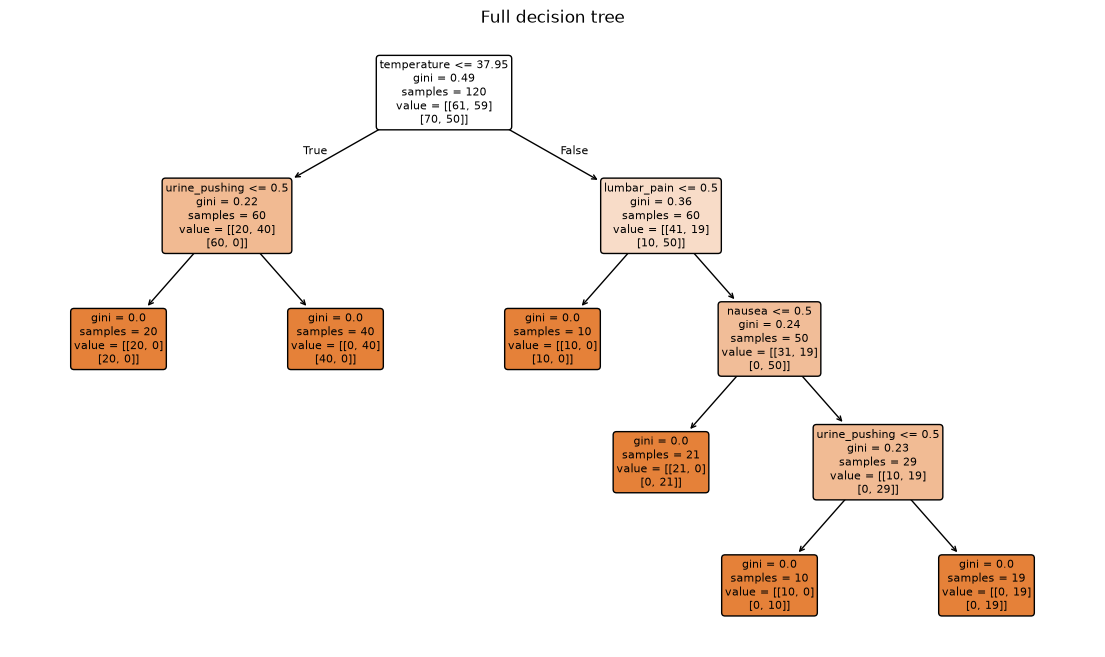

In [3]:
full_tree = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X, y)
print(f'Training accuracy: {full_tree.score(X, y):.1%}')
print(f'Depth: {full_tree.get_depth()}, leaves: {full_tree.get_n_leaves()}')
plt.figure(figsize=(14, 8))
plot_tree(full_tree, feature_names=feature_names, filled=True, rounded=True,
          precision=2, fontsize=8)
plt.title('Full decision tree')
plt.show()

### (c) Convert the tree to IF-THEN rules

In [4]:
def print_rules(model):
    tree = model.tree_

    def visit(node, conditions):
        if tree.children_left[node] == tree.children_right[node]:
            labels = [model.classes_[j][np.argmax(tree.value[node, j])]
                      for j in range(2)]
            result = ', '.join(f'{name} = {"yes" if label else "no"}'
                               for name, label in zip(target_names, labels))
            print('IF ' + (' AND '.join(conditions) or 'TRUE') + ' THEN ' + result)
            return
        feature = feature_names[tree.feature[node]]
        threshold = tree.threshold[node]
        if feature == 'temperature':
            left, right = f'{feature} <= {threshold:.2f} C', f'{feature} > {threshold:.2f} C'
        else:
            left, right = f'{feature} = no', f'{feature} = yes'
        visit(tree.children_left[node], conditions + [left])
        visit(tree.children_right[node], conditions + [right])

    visit(0, [])

print_rules(full_tree)

IF temperature <= 37.95 C AND urine_pushing = no THEN bladder_inflammation = no, renal_pelvis_nephritis = no
IF temperature <= 37.95 C AND urine_pushing = yes THEN bladder_inflammation = yes, renal_pelvis_nephritis = no
IF temperature > 37.95 C AND lumbar_pain = no THEN bladder_inflammation = no, renal_pelvis_nephritis = no
IF temperature > 37.95 C AND lumbar_pain = yes AND nausea = no THEN bladder_inflammation = no, renal_pelvis_nephritis = yes
IF temperature > 37.95 C AND lumbar_pain = yes AND nausea = yes AND urine_pushing = no THEN bladder_inflammation = no, renal_pelvis_nephritis = yes
IF temperature > 37.95 C AND lumbar_pain = yes AND nausea = yes AND urine_pushing = yes THEN bladder_inflammation = yes, renal_pelvis_nephritis = yes


### (d) Cost-complexity pruning for interpretability

Larger `ccp_alpha` values give smaller trees. I compared the pruning candidates using five-fold CV, keeping the diagnosis combinations balanced across folds. I chose the smallest tree with at least 85% mean CV accuracy as a simple accuracy/simplicity tradeoff. These CV scores are for selection, not an independent test.

In [5]:
alphas = full_tree.cost_complexity_pruning_path(X, y).ccp_alphas
joint_labels = y.astype(str).agg('_'.join, axis=1)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv.split(X, joint_labels))
results = []

for alpha in np.unique(alphas):
    model = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=alpha)
    score = cross_val_score(model, X, y, cv=folds, scoring='accuracy').mean()
    model.fit(X, y)
    results.append([alpha, model.get_n_leaves(), score])

results = pd.DataFrame(results, columns=['alpha', 'leaves', 'CV accuracy'])
display(results.round(4))
chosen = results[results['CV accuracy'] >= 0.85].sort_values('leaves').iloc[0]
pruned_tree = DecisionTreeClassifier(random_state=RANDOM_STATE,
                                     ccp_alpha=chosen['alpha']).fit(X, y)

,alpha,leaves,CV accuracy
0,0.0000,6,1.0000
1,0.0491,4,0.8667
2,0.0795,3,0.7667
3,0.1111,2,0.6333
4,0.2042,1,0.4500


In [6]:
display(pd.DataFrame({
    'Tree': ['Full', 'Pruned'],
    'Depth': [full_tree.get_depth(), pruned_tree.get_depth()],
    'Rules': [full_tree.get_n_leaves(), pruned_tree.get_n_leaves()],
    'Training accuracy': [full_tree.score(X, y), pruned_tree.score(X, y)]
}))

,Tree,Depth,Rules,Training accuracy
0,Full,4,6,1.000000
1,Pruned,2,4,0.841667


The pruned tree has four rules and depth two, compared with six rules and depth four before pruning. Its CV accuracy is 86.7%, versus 100% for the full tree. It is easier to read, but it misses some patients with both diagnoses.

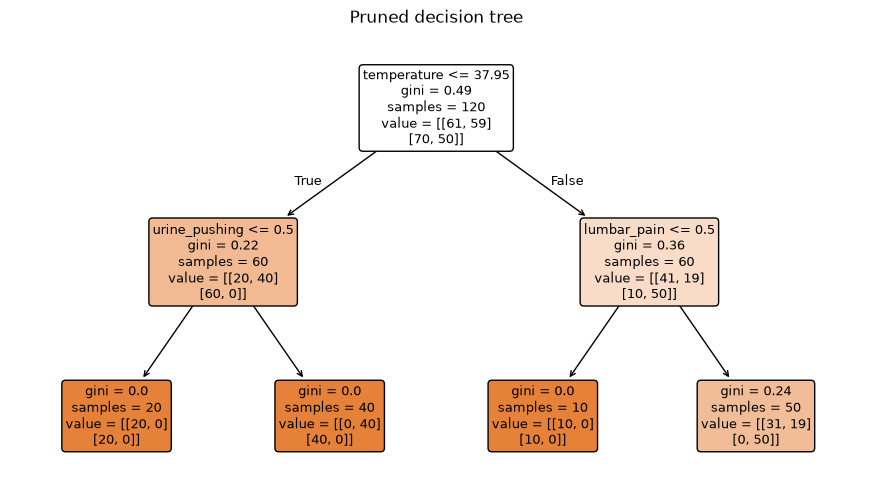

IF temperature <= 37.95 C AND urine_pushing = no THEN bladder_inflammation = no, renal_pelvis_nephritis = no
IF temperature <= 37.95 C AND urine_pushing = yes THEN bladder_inflammation = yes, renal_pelvis_nephritis = no
IF temperature > 37.95 C AND lumbar_pain = no THEN bladder_inflammation = no, renal_pelvis_nephritis = no
IF temperature > 37.95 C AND lumbar_pain = yes THEN bladder_inflammation = no, renal_pelvis_nephritis = yes


In [7]:
plt.figure(figsize=(11, 6))
plot_tree(pruned_tree, feature_names=feature_names, filled=True, rounded=True,
          precision=2, fontsize=9)
plt.title('Pruned decision tree')
plt.show()
print_rules(pruned_tree)

## 2. Communities and Crime

### (a) Load the data and split into training and test sets

In [8]:
columns = [line.split()[1]
           for line in (DATA_DIR / 'communities.names').read_text().splitlines()
           if line.lower().startswith('@attribute')]
communities = pd.read_csv(DATA_DIR / 'communities.data', header=None,
                          names=columns, na_values='?')

train_data = communities.iloc[:1495].copy()
test_data = communities.iloc[1495:].copy()

print('Training set:', train_data.shape)
print('Test set:', test_data.shape)

Training set: (1495, 128)
Test set: (499, 128)


### (b) Handle missing values and remove nonpredictive features

I dropped `state`, `county`, `community`, `communityname`, and `fold`. I filled missing predictors with their training-set medians and used the same values for the test set to avoid data leakage. `ViolentCrimesPerPop` is the target.

In [9]:
nonpredictive = ['state', 'county', 'community', 'communityname', 'fold']
target = 'ViolentCrimesPerPop'
X_train = train_data.drop(columns=nonpredictive + [target])
X_test = test_data.drop(columns=nonpredictive + [target])
y_train = train_data[target].copy()
y_test = test_data[target].copy()

imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(X_train),
                       columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test),
                      columns=X_test.columns, index=X_test.index)

print('Training predictors:', X_train.shape)
print('Test predictors:', X_test.shape)
print('Missing values after imputation:',
      X_train.isna().sum().sum() + X_test.isna().sum().sum())

Training predictors: (1495, 122)
Test predictors: (499, 122)
Missing values after imputation: 0


### (c) Correlation matrix

I plotted Pearson correlations between the 122 imputed training features. Red shows positive correlation, and blue shows negative correlation.

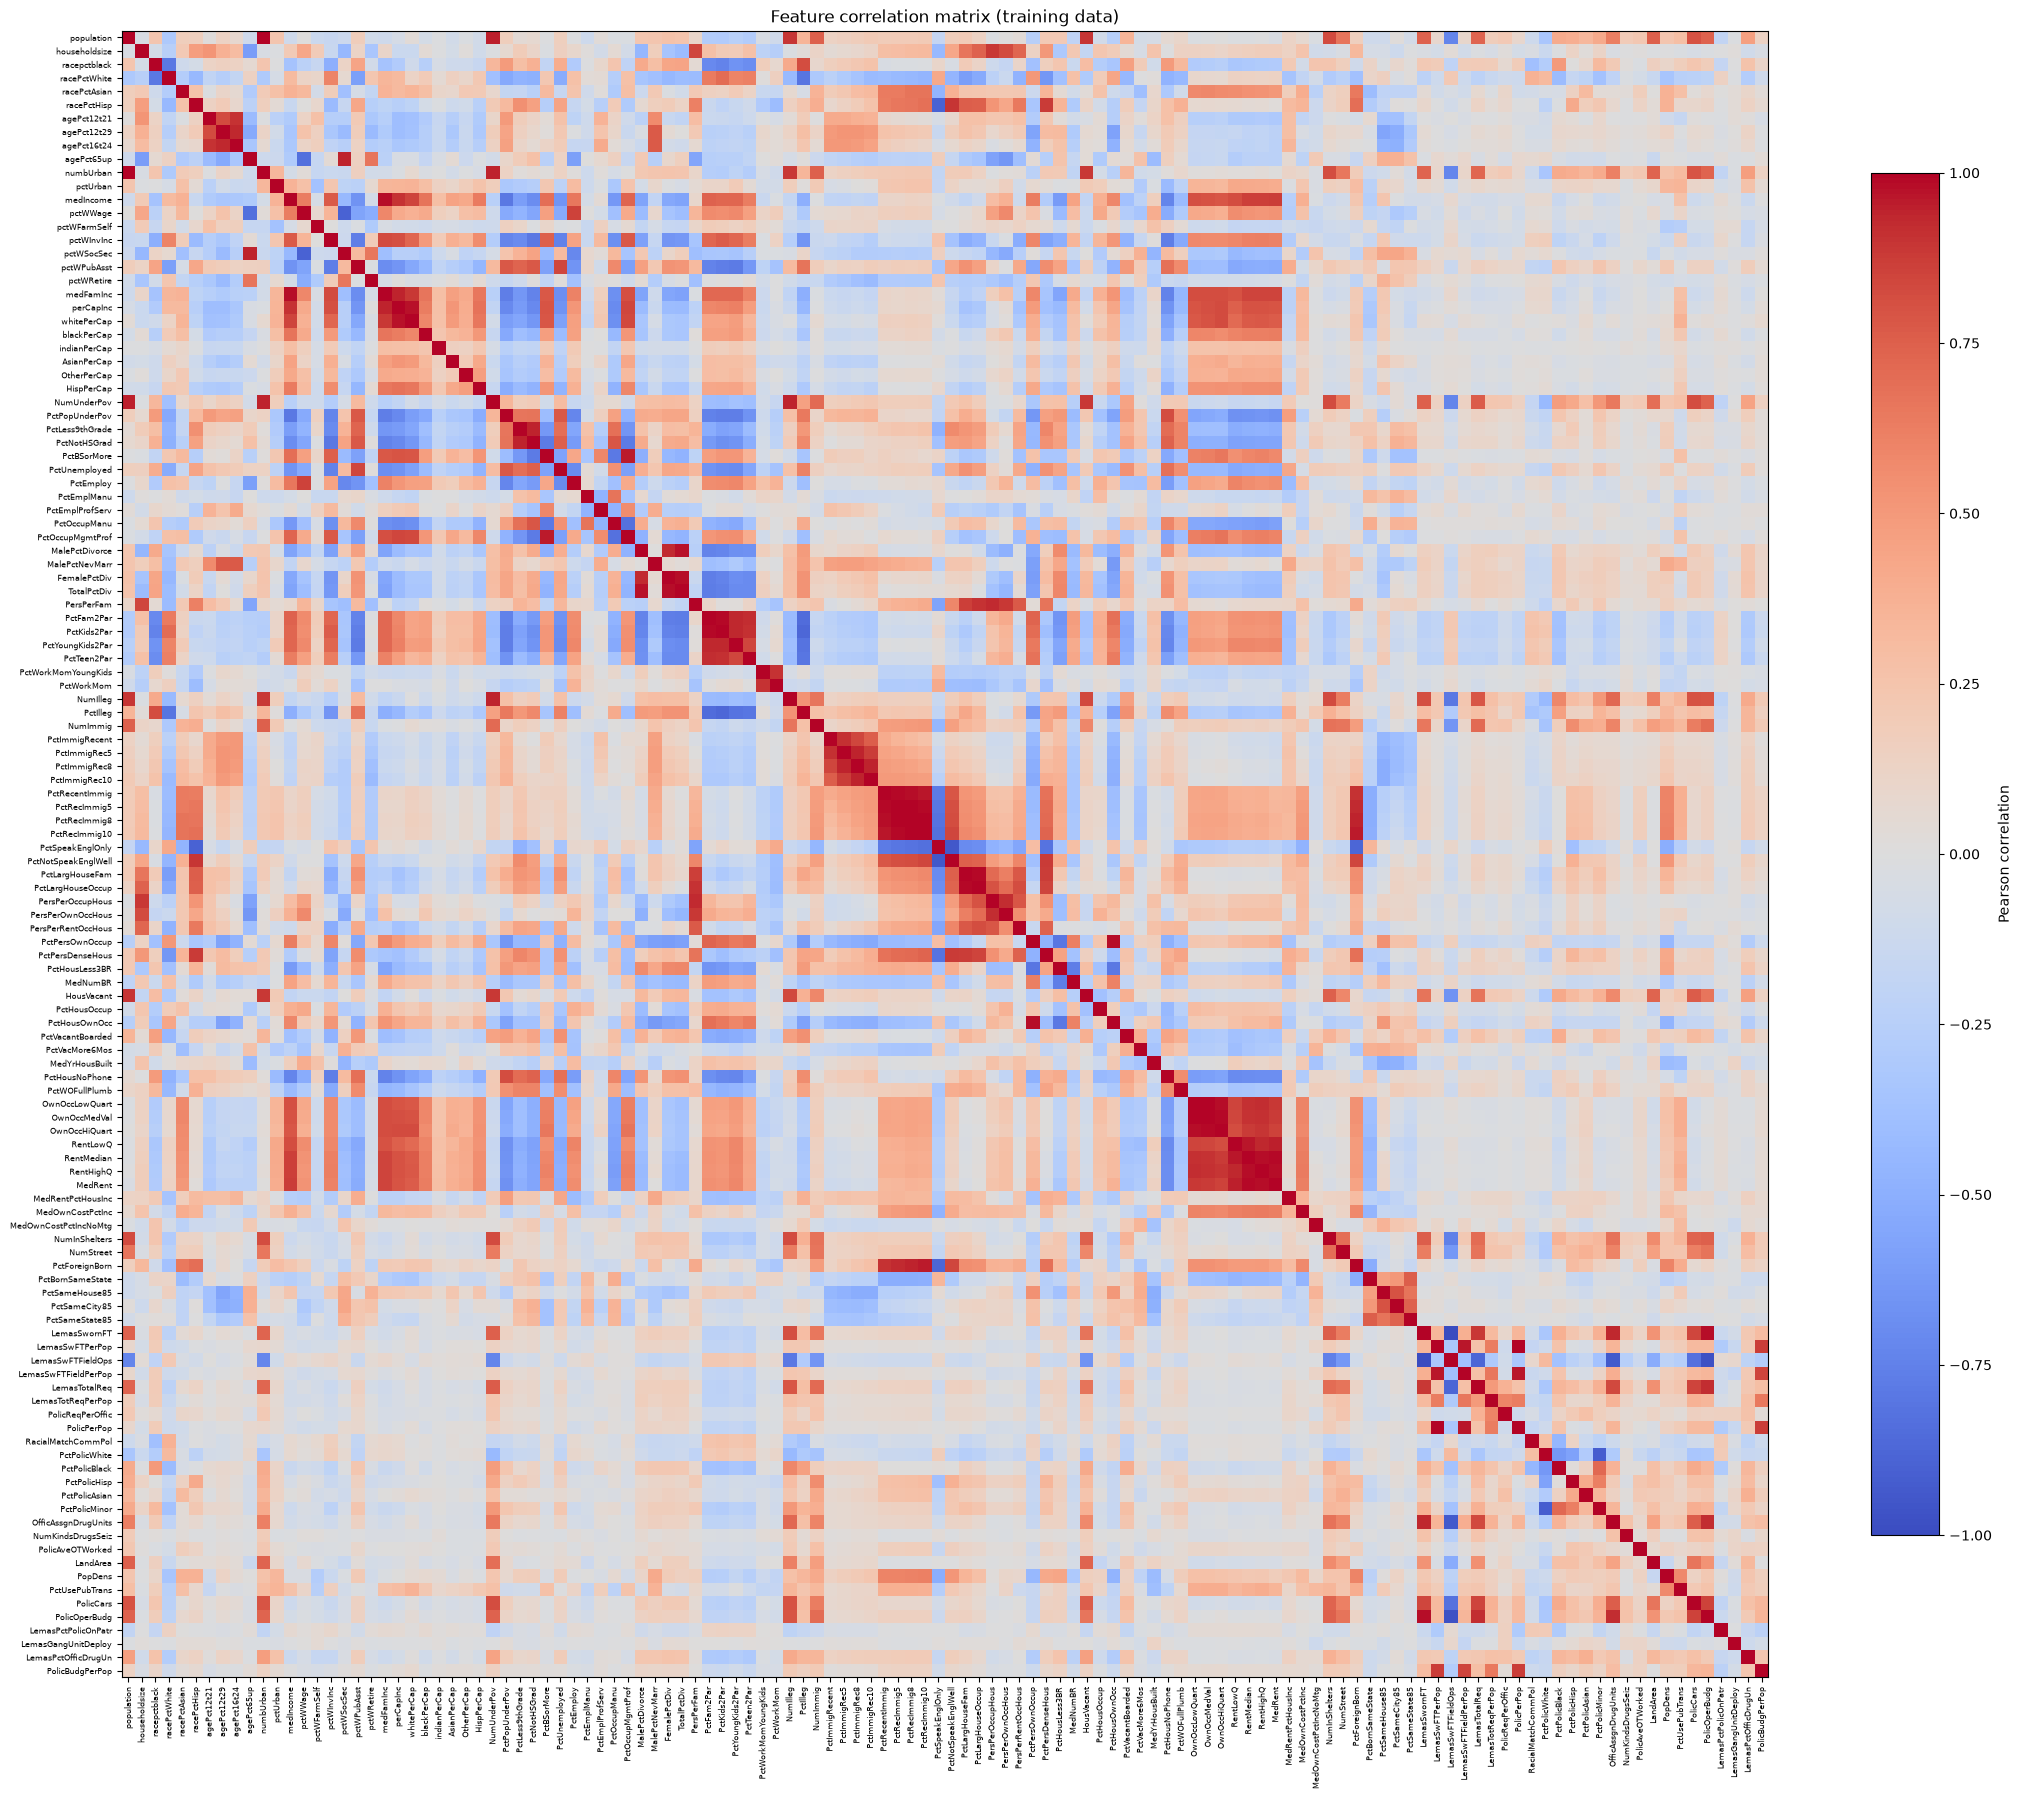

In [10]:
corr = X_train.corr()
fig, ax = plt.subplots(figsize=(22, 20))
heatmap = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=6)
ax.set_yticks(range(len(corr)), corr.index, fontsize=6)
fig.colorbar(heatmap, ax=ax, shrink=0.7, label='Pearson correlation')
ax.set_title('Feature correlation matrix (training data)')
plt.tight_layout()
plt.show()

### (d) Coefficient of variation

I calculated CV = sample standard deviation / sample mean using the imputed training features. CV is undefined when the mean is zero.

In [11]:
feature_cv = X_train.std(ddof=1) / X_train.mean().replace(0, np.nan)
with pd.option_context('display.max_rows', None):
    display(feature_cv.rename('CV').to_frame().round(3))

,CV
population,2.241
householdsize,0.356
racepctblack,1.429
racePctWhite,0.330
racePctAsian,1.359
racePctHisp,1.612
agePct12t21,0.369
agePct12t29,0.291
agePct16t24,0.500
agePct65up,0.413


### (e) Features with the highest CV

I picked floor(sqrt(128)) = 11 features and plotted each against the crime rate, along with box plots.

Selected features: PctPolicAsian, NumStreet, NumInShelters, NumIlleg, NumImmig, LemasPctOfficDrugUn, NumUnderPov, LemasSwornFT, population, numbUrban, HousVacant


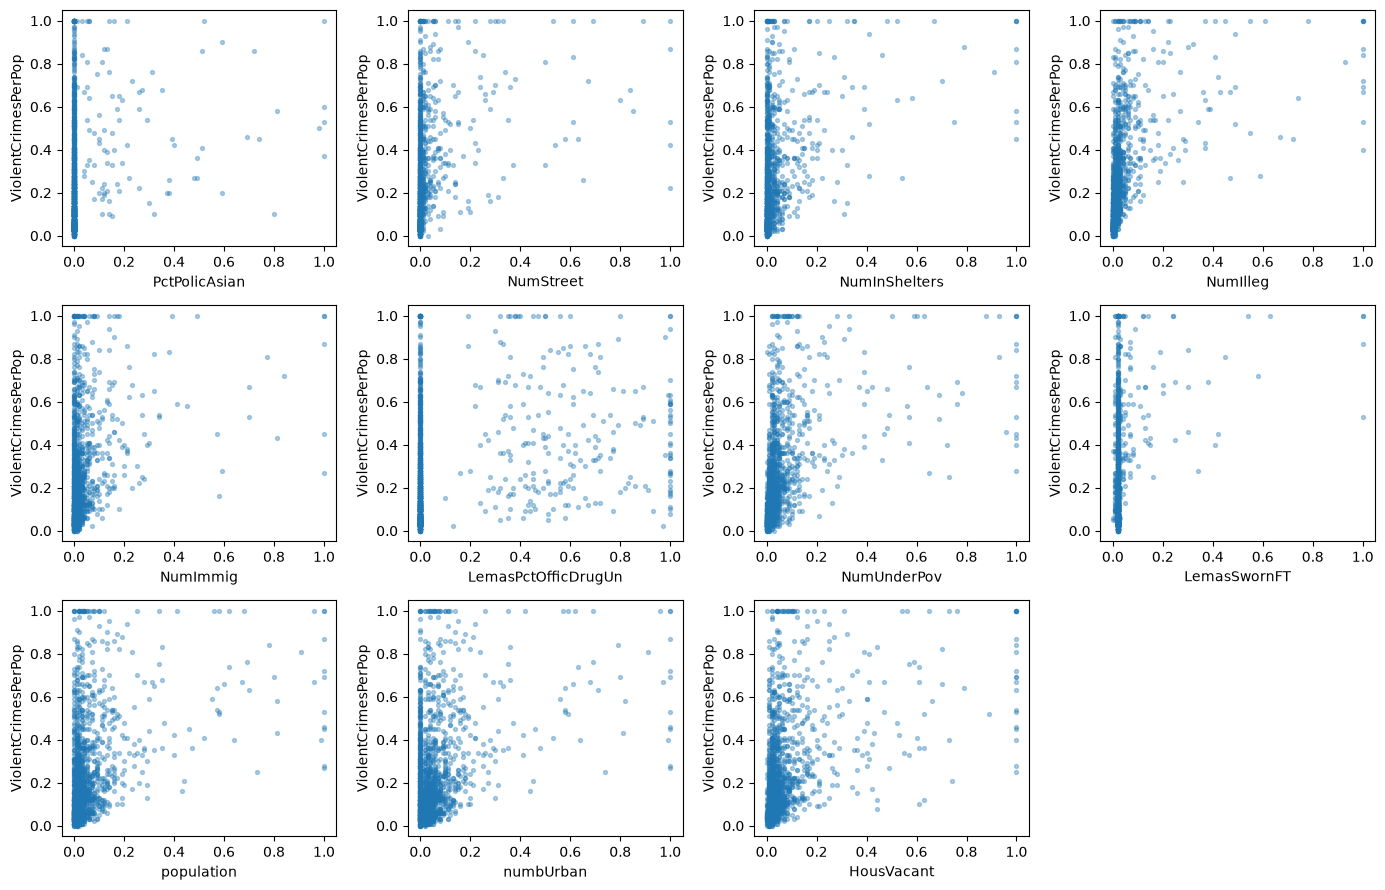

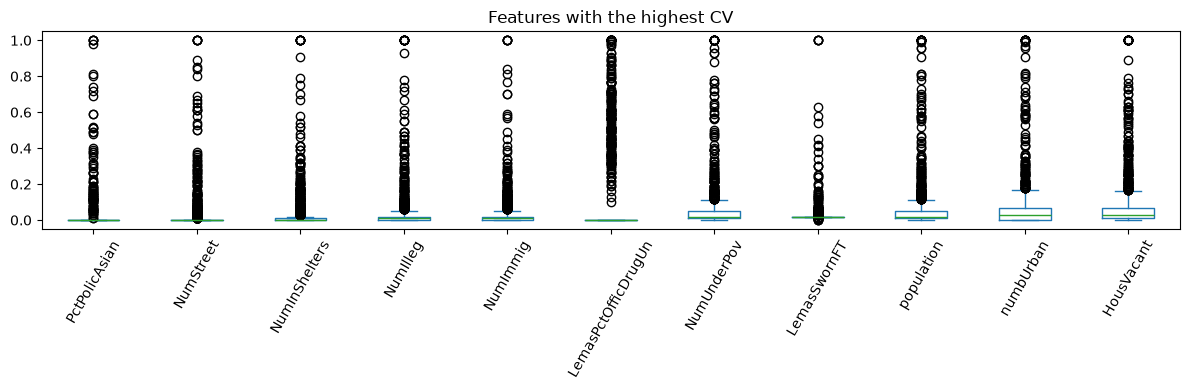

In [12]:
top_features = feature_cv.nlargest(int(np.sqrt(128))).index
print('Selected features:', ', '.join(top_features))

fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for ax, feature in zip(axes.flat, top_features):
    ax.scatter(X_train[feature], y_train, s=8, alpha=0.35)
    ax.set(xlabel=feature, ylabel='ViolentCrimesPerPop')
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

X_train[top_features].plot.box(figsize=(12, 4), rot=60)
plt.title('Features with the highest CV')
plt.tight_layout()
plt.show()

**Conclusions from the scatter plots and box plots**

The 11 highest-CV features are mostly count variables (`population`, `numbUrban`, `NumUnderPov`, `NumInShelters`, `NumStreet`, `NumIlleg`, `NumImmig`, `HousVacant`) and LEMAS police-department variables (`LemasSwornFT`, `LemasPctOfficDrugUn`, `PctPolicAsian`). They have high CV because they are extremely right-skewed: most communities have values near 0, and a few large cities sit near 1. The box plots show this, with the boxes squashed near zero and many outliers above them.

The scatter plots show:
- **Count features** (`population`, `NumUnderPov`, `NumIlleg`, `NumInShelters`, `NumStreet`, `HousVacant`, etc.) show a weak positive trend. The few communities with large values tend to have higher crime rates, but the bulk of the points are crowded near zero, where crime ranges from about 0 to 0.8. The relationship looks like a fan shape rather than a clean line.
- **LEMAS and police features** (`LemasSwornFT`, `PctPolicAsian`, `LemasPctOfficDrugUn`) form a vertical stripe at or near zero. This is partly because most of these values were missing and were median-imputed, so the stripe holds little real information. Any apparent trend rests on a handful of points.

I can't draw reliable conclusions about significance from these plots alone, for four reasons:
1. The scatter plots show only marginal, one-feature-at-a-time relationships. They can't account for the other 121 features, and many of these features are highly correlated with each other (e.g., `population`, `numbUrban`, `NumUnderPov` all measure community size).
2. Heavy skew and outliers mean a few points can create or hide a visible trend.
3. A scatter plot gives no p-value, confidence interval, or effect size.
4. High CV measures relative spread, not predictive power. A feature can vary a lot and still be unrelated to crime.

Judging which features matter requires a model-based approach, such as the regression coefficients, LASSO selection, or cross-validated performance in the later parts.

### (f) Least squares regression

I used all 122 predictors and report mean squared error (MSE) on the test set. The top 11 features were only used for the plots.

In [13]:
ols = LinearRegression().fit(X_train, y_train)
test_errors = {'Least squares': mean_squared_error(y_test, ols.predict(X_test))}
print(f"Test MSE: {test_errors['Least squares']:.5f}")

Test MSE: 0.01797


### (g) Ridge regression

I chose lambda (`alpha` in sklearn) using five-fold CV with MSE. Imputation and scaling are fitted inside each fold. The test set is only used for the final error.

In [14]:
X_train_raw = train_data[X_train.columns]
X_test_raw = test_data[X_train.columns]
regression_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

ridge = GridSearchCV(
    Pipeline([('imputer', SimpleImputer(strategy='median')),
              ('scaler', StandardScaler()), ('model', Ridge())]),
    {'model__alpha': np.logspace(-4, 4, 25)},
    cv=regression_cv, scoring='neg_mean_squared_error')
ridge.fit(X_train_raw, y_train)
test_errors['Ridge'] = mean_squared_error(y_test, ridge.predict(X_test_raw))
print(f"Chosen lambda: {ridge.best_params_['model__alpha']:.6g}")
print(f"Test MSE: {test_errors['Ridge']:.5f}")

Chosen lambda: 100
Test MSE: 0.01740


### (h) LASSO with and without standardization

I chose lambda separately for each version using the same five folds. Features with nonzero coefficients are selected. Standardization changes the penalty applied to each feature.

In [15]:
lasso_models = {}
for name, scaler in [('LASSO (original scale)', 'passthrough'),
                     ('LASSO (standardized)', StandardScaler())]:
    search = GridSearchCV(
        Pipeline([('imputer', SimpleImputer(strategy='median')),
                  ('scaler', scaler), ('model', Lasso(max_iter=30000))]),
        {'model__alpha': np.logspace(-5, 0, 31)},
        cv=regression_cv, scoring='neg_mean_squared_error')
    search.fit(X_train_raw, y_train)
    lasso_models[name] = search
    test_errors[name] = mean_squared_error(y_test, search.predict(X_test_raw))
    selected = X_train.columns[search.best_estimator_['model'].coef_ != 0]
    print(f"{name}: lambda = {search.best_params_['model__alpha']:.6g}, "
          f"test MSE = {test_errors[name]:.5f}")
    print(f'Selected features ({len(selected)}):', ', '.join(selected), '\n')

raw_mse = test_errors['LASSO (original scale)']
scaled_mse = test_errors['LASSO (standardized)']
print('Standardization ' + ('lowered' if scaled_mse < raw_mse else 'did not lower')
      + f' the test MSE ({raw_mse:.5f} vs. {scaled_mse:.5f}).')

LASSO (original scale): lambda = 0.0001, test MSE = 0.01766
Selected features (75): racepctblack, racePctAsian, agePct12t21, agePct12t29, agePct65up, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctBSorMore, PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRec10, PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctSameCity85, LemasSwFTFieldPerPop, LemasTotalReq, PolicReqPerOffic, RacialMat

LASSO (standardized): lambda = 0.000681292, test MSE = 0.01771
Selected features (76): racepctblack, racePctAsian, agePct12t21, agePct12t29, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRecent, PctImmigRec5, PctImmigRec10, PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctSameCity85, LemasSwFTFieldPerPop, LemasTotalReq, PolicReqPerOffic, R

### (i) Principal component regression (PCR)

I standardized the features, applied PCA, and fit least squares to the components. I chose M by five-fold CV from 1 to 122, fitting preprocessing inside each fold.

In [16]:
component_choices = list(range(1, X_train.shape[1] + 1))
pcr = GridSearchCV(
    Pipeline([('imputer', SimpleImputer(strategy='median')),
              ('scaler', StandardScaler()), ('pca', PCA(svd_solver='full')),
              ('model', LinearRegression())]),
    {'pca__n_components': component_choices},
    cv=regression_cv, scoring='neg_mean_squared_error')
pcr.fit(X_train_raw, y_train)
test_errors['PCR'] = mean_squared_error(y_test, pcr.predict(X_test_raw))
print('Chosen M:', pcr.best_params_['pca__n_components'])
print(f"Test MSE: {test_errors['PCR']:.5f}")
display(pd.Series(test_errors, name='Test MSE').to_frame().round(5))

Chosen M: 60
Test MSE: 0.01835


,Test MSE
Least squares,0.01797
Ridge,0.01740
LASSO (original scale),0.01766
LASSO (standardized),0.01771
PCR,0.01835


### (j) L1-penalized gradient boosting

I used XGBoost with 300 trees, depth 3, and learning rate 0.05. I chose alpha using five-fold CV with MSE and kept the test set separate. In XGBoost, [`reg_alpha`](https://xgboost.readthedocs.io/en/stable/parameter.html) applies the L1 penalty to leaf weights. I set the L2 penalty to zero.

In [17]:
boosting = GridSearchCV(
    Pipeline([('imputer', SimpleImputer(strategy='median')),
              ('model', XGBRegressor(objective='reg:squarederror',
                                     n_estimators=300, max_depth=3,
                                     learning_rate=0.05, reg_lambda=0,
                                     tree_method='hist', n_jobs=1,
                                     random_state=RANDOM_STATE))]),
    {'model__reg_alpha': [0, 0.001, 0.01, 0.1, 1, 10, 100]},
    cv=regression_cv, scoring='neg_mean_squared_error')
boosting.fit(X_train_raw, y_train)

display(pd.DataFrame({
    'alpha': [p['model__reg_alpha'] for p in boosting.cv_results_['params']],
    'CV MSE': -boosting.cv_results_['mean_test_score']
}).round(5))
test_errors['XGBoost'] = mean_squared_error(y_test, boosting.predict(X_test_raw))
print('Chosen alpha:', boosting.best_params_['model__reg_alpha'])
print(f"Test MSE: {test_errors['XGBoost']:.5f}")

,alpha,CV MSE
0,0.000,0.02065
1,0.001,0.02096
2,0.010,0.02067
3,0.100,0.02014
4,1.000,0.02007
5,10.000,0.02192
6,100.000,0.05661


Chosen alpha: 1
Test MSE: 0.01670
